# 综合实验 1 文本分析 · 任务 11：关键字查询与单店分析

演示流程：**输入关键词 → 候选商户列表 → 选择商户 → 词云 / 好评率 / 雷达图 / 周趋势**。
本 notebook 用 `keyword="湘"`、选择 `57℃湘(无限度广场店)` 作为演示；函数 `run_query()` 支持交互输入。

In [1]:
import sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

SRC = "D:/DSH-Workspaces/数据科学/综合实验1/src"
sys.path.insert(0, SRC)
from config import TAB, FIG
import data_utils, text_utils, viz_utils
from agg_utils import (search_restaurants, restaurant_slice,
                       restaurant_weekly, weekly_counts, rolling_ratio)
from text_utils import tokenize

text_utils.ensure_init(str(TAB.parents[1] / "stopwords.txt"),
                       str(TAB.parents[1] / "userdict.txt"))
viz_utils.set_cn_font()
pd.set_option("display.width", 200)

agg = pd.read_csv(TAB / "rest_agg.csv")
print("商户宽表:", agg.shape)

Building prefix dict from the default dictionary ...


Loading model from cache C:\Users\13727\AppData\Local\Temp\jieba.cache


Loading model cost 0.426 seconds.


Prefix dict has been built successfully.


商户宽表: (241360, 25)


In [2]:
keyword = "湘"
cands = search_restaurants(keyword, agg, topk=20)
print(f"关键词「{keyword}」命中 {len(cands)} 个候选（按极化样本量排序，Top20）：")
cands[["display", "n", "lab", "ratio", "命中方式"]].round(4)

关键词「湘」命中 20 个候选（按极化样本量排序，Top20）：


,display,n,lab,ratio,命中方式
200095,201535 | 红辣椒(张杨路店),209,185,0.9784,评论
196410,197839 | 辛香汇(大悦城店),208,175,0.9486,评论
176139,177416 | 57℃湘(无限度广场店),207,160,0.9438,名称+评论
227266,228954 | 伊秀手握寿司(金桥国际店),198,160,0.9625,评论
197918,199351 | restId=199351（无名称）,184,157,0.9936,评论
162476,163616 | 麻辣诱惑(淮海路店),185,154,0.9935,评论
79028,79493 | 王品台塑牛排(徐家汇店),171,150,1.0000,评论
221307,222986 | restId=222986（无名称）,169,146,0.9863,评论
144898,145920 | restId=145920（无名称）,146,145,0.9793,评论
222018,223697 | restId=223697（无名称）,196,144,0.9514,评论


In [3]:
DEMO_ID = 177416          # 57℃湘(无限度广场店)：评论多、周均有效样本约 9 条
row = agg[agg["restId"] == DEMO_ID].iloc[0]
DEMO_NAME = row["name"] if isinstance(row["name"], str) else f"restId={DEMO_ID}"
print("演示商户:", DEMO_ID, DEMO_NAME)
print("评论数 %d | 好评 %d | 差评 %d | 极化好评率 %.3f | 环境/口味/服务 %.2f/%.2f/%.2f" % (
    row["n"], row["good"], row["bad"], row["ratio"],
    row["env_mean"], row["flavor_mean"], row["service_mean"]))

演示商户: 177416 57℃湘(无限度广场店)
评论数 207 | 好评 151 | 差评 9 | 极化好评率 0.944 | 环境/口味/服务 3.26/3.14/3.11


## 11.2 该商户的评论 / 好评 / 差评词云

In [4]:
sub = restaurant_slice([DEMO_ID], usecols=("restId", "rating", "timestamp", "comment"))
sub["label"] = data_utils.encode_label(sub["rating"], "A")
print("该店评论行数:", len(sub), "| 好评:", int((sub["label"] == 1).sum()),
      "| 差评:", int((sub["label"] == 0).sum()))

counters = {"all": Counter(), "good": Counter(), "bad": Counter()}
for _, r in sub.iterrows():
    toks = tokenize(r["comment"])
    counters["all"].update(t for t in toks if len(t) >= 2)
    if r["label"] == 1:
        counters["good"].update(t for t in toks if len(t) >= 2)
    elif r["label"] == 0:
        counters["bad"].update(t for t in toks if len(t) >= 2)
print("all 词表:", len(counters["all"]), "| good:", len(counters["good"]), "| bad:", len(counters["bad"]))

该店评论行数: 207 | 好评: 151 | 差评: 9
all 词表: 3206 | good: 2525 | bad: 309


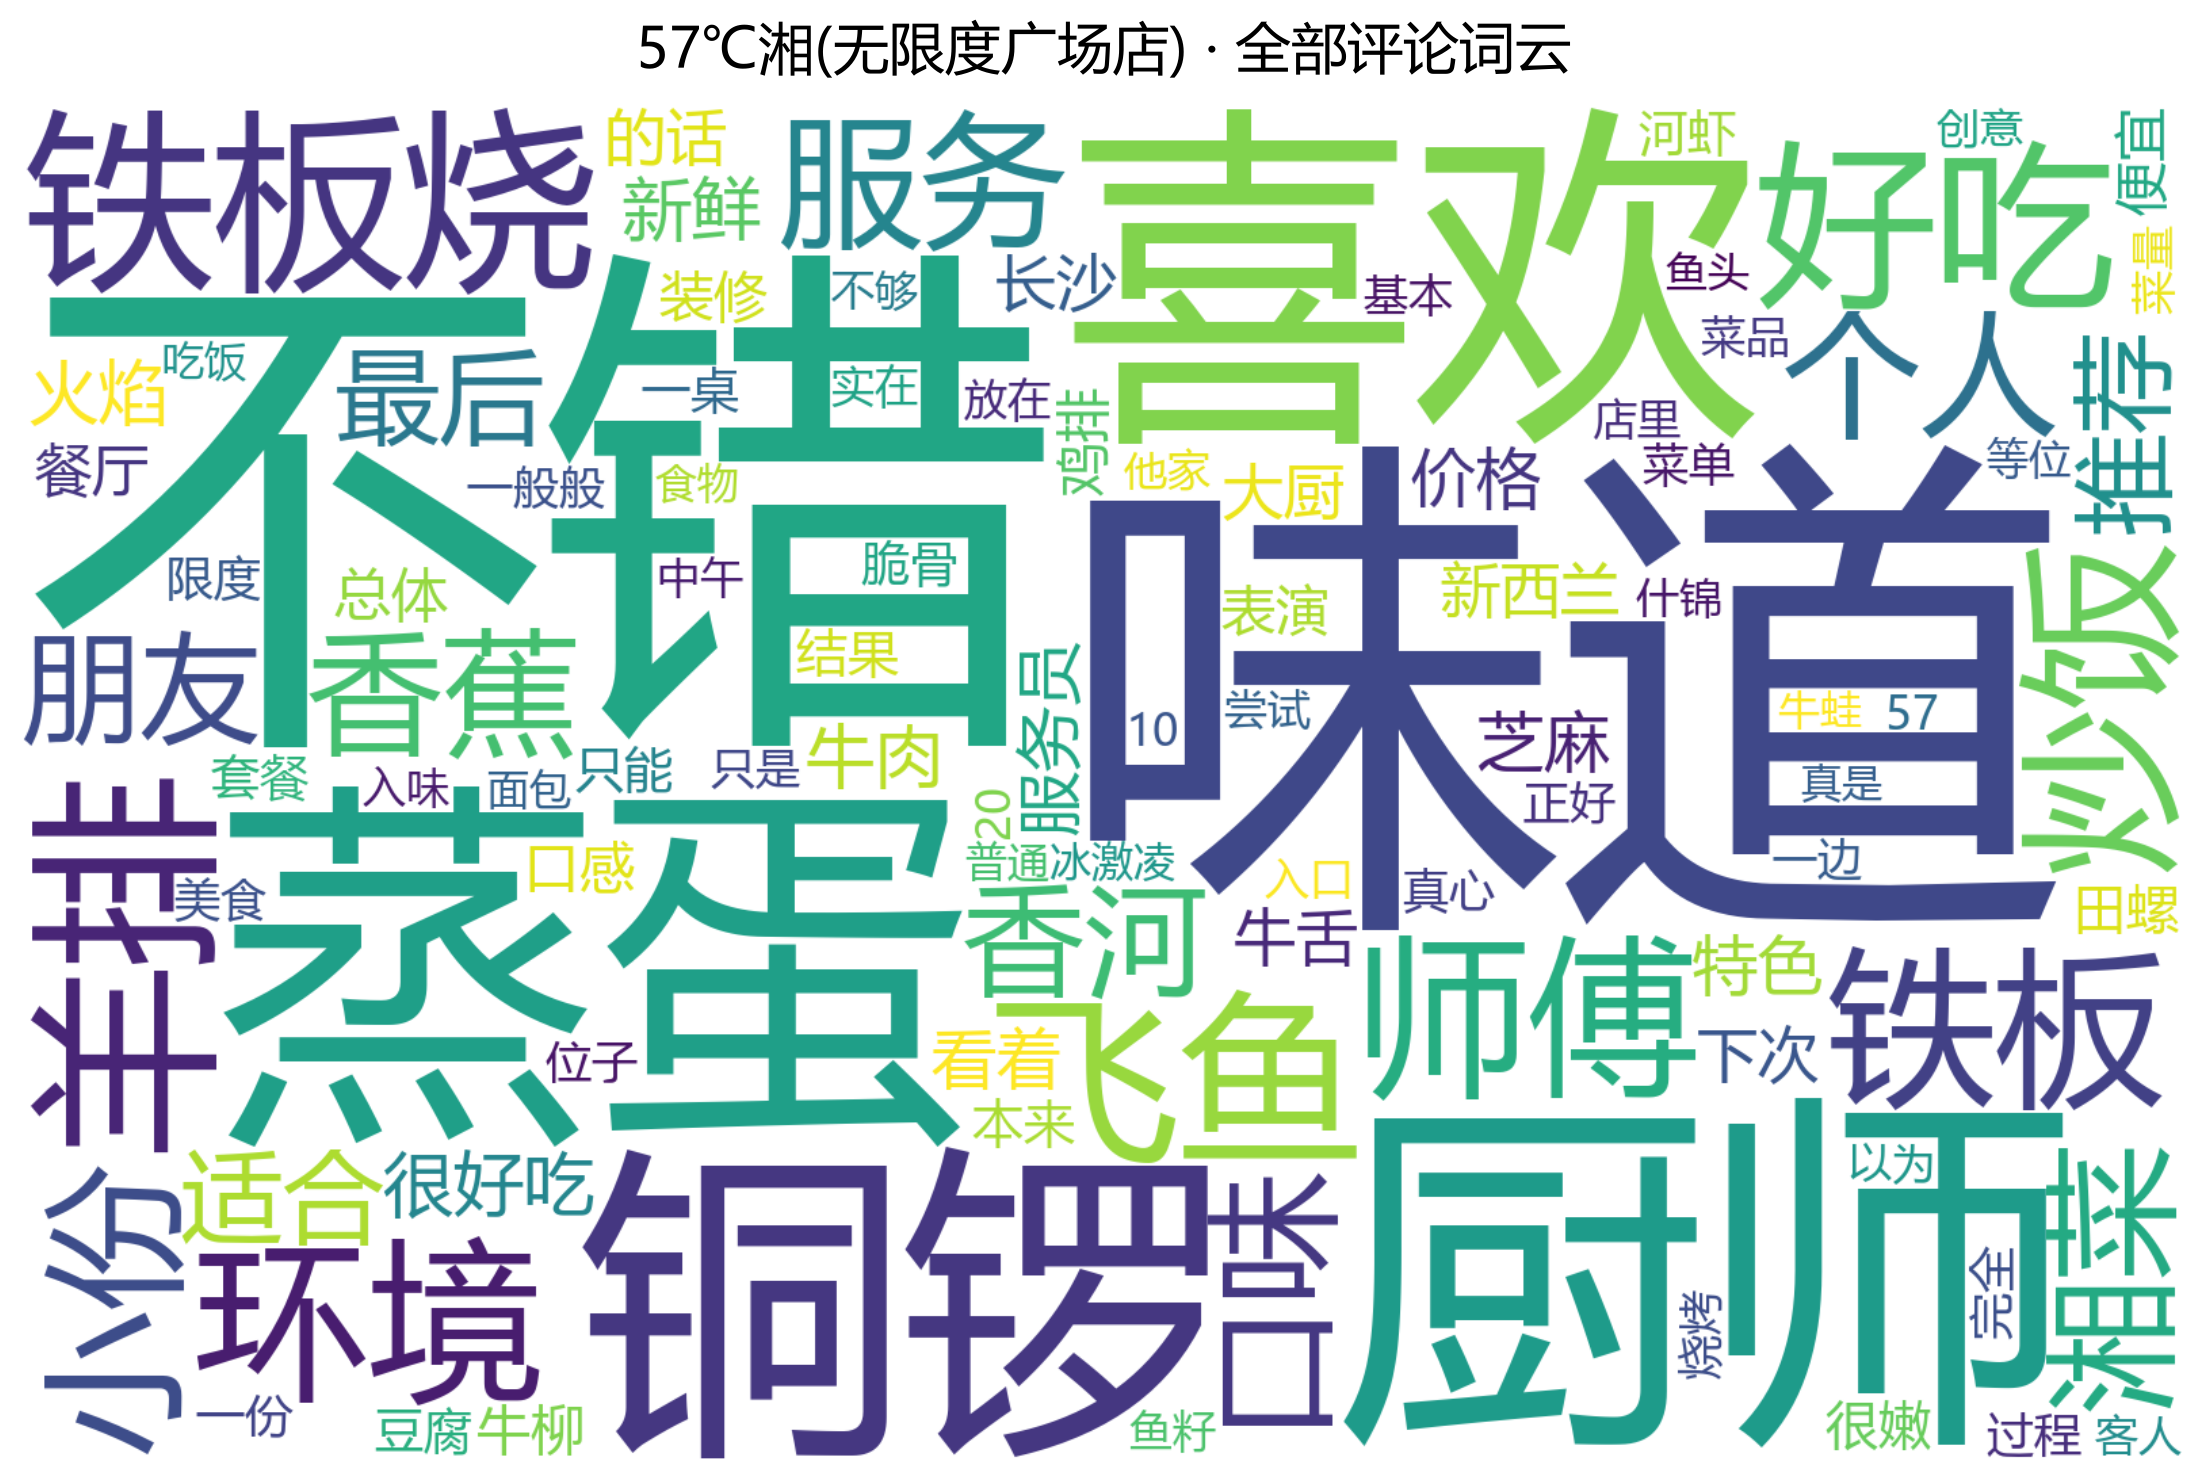

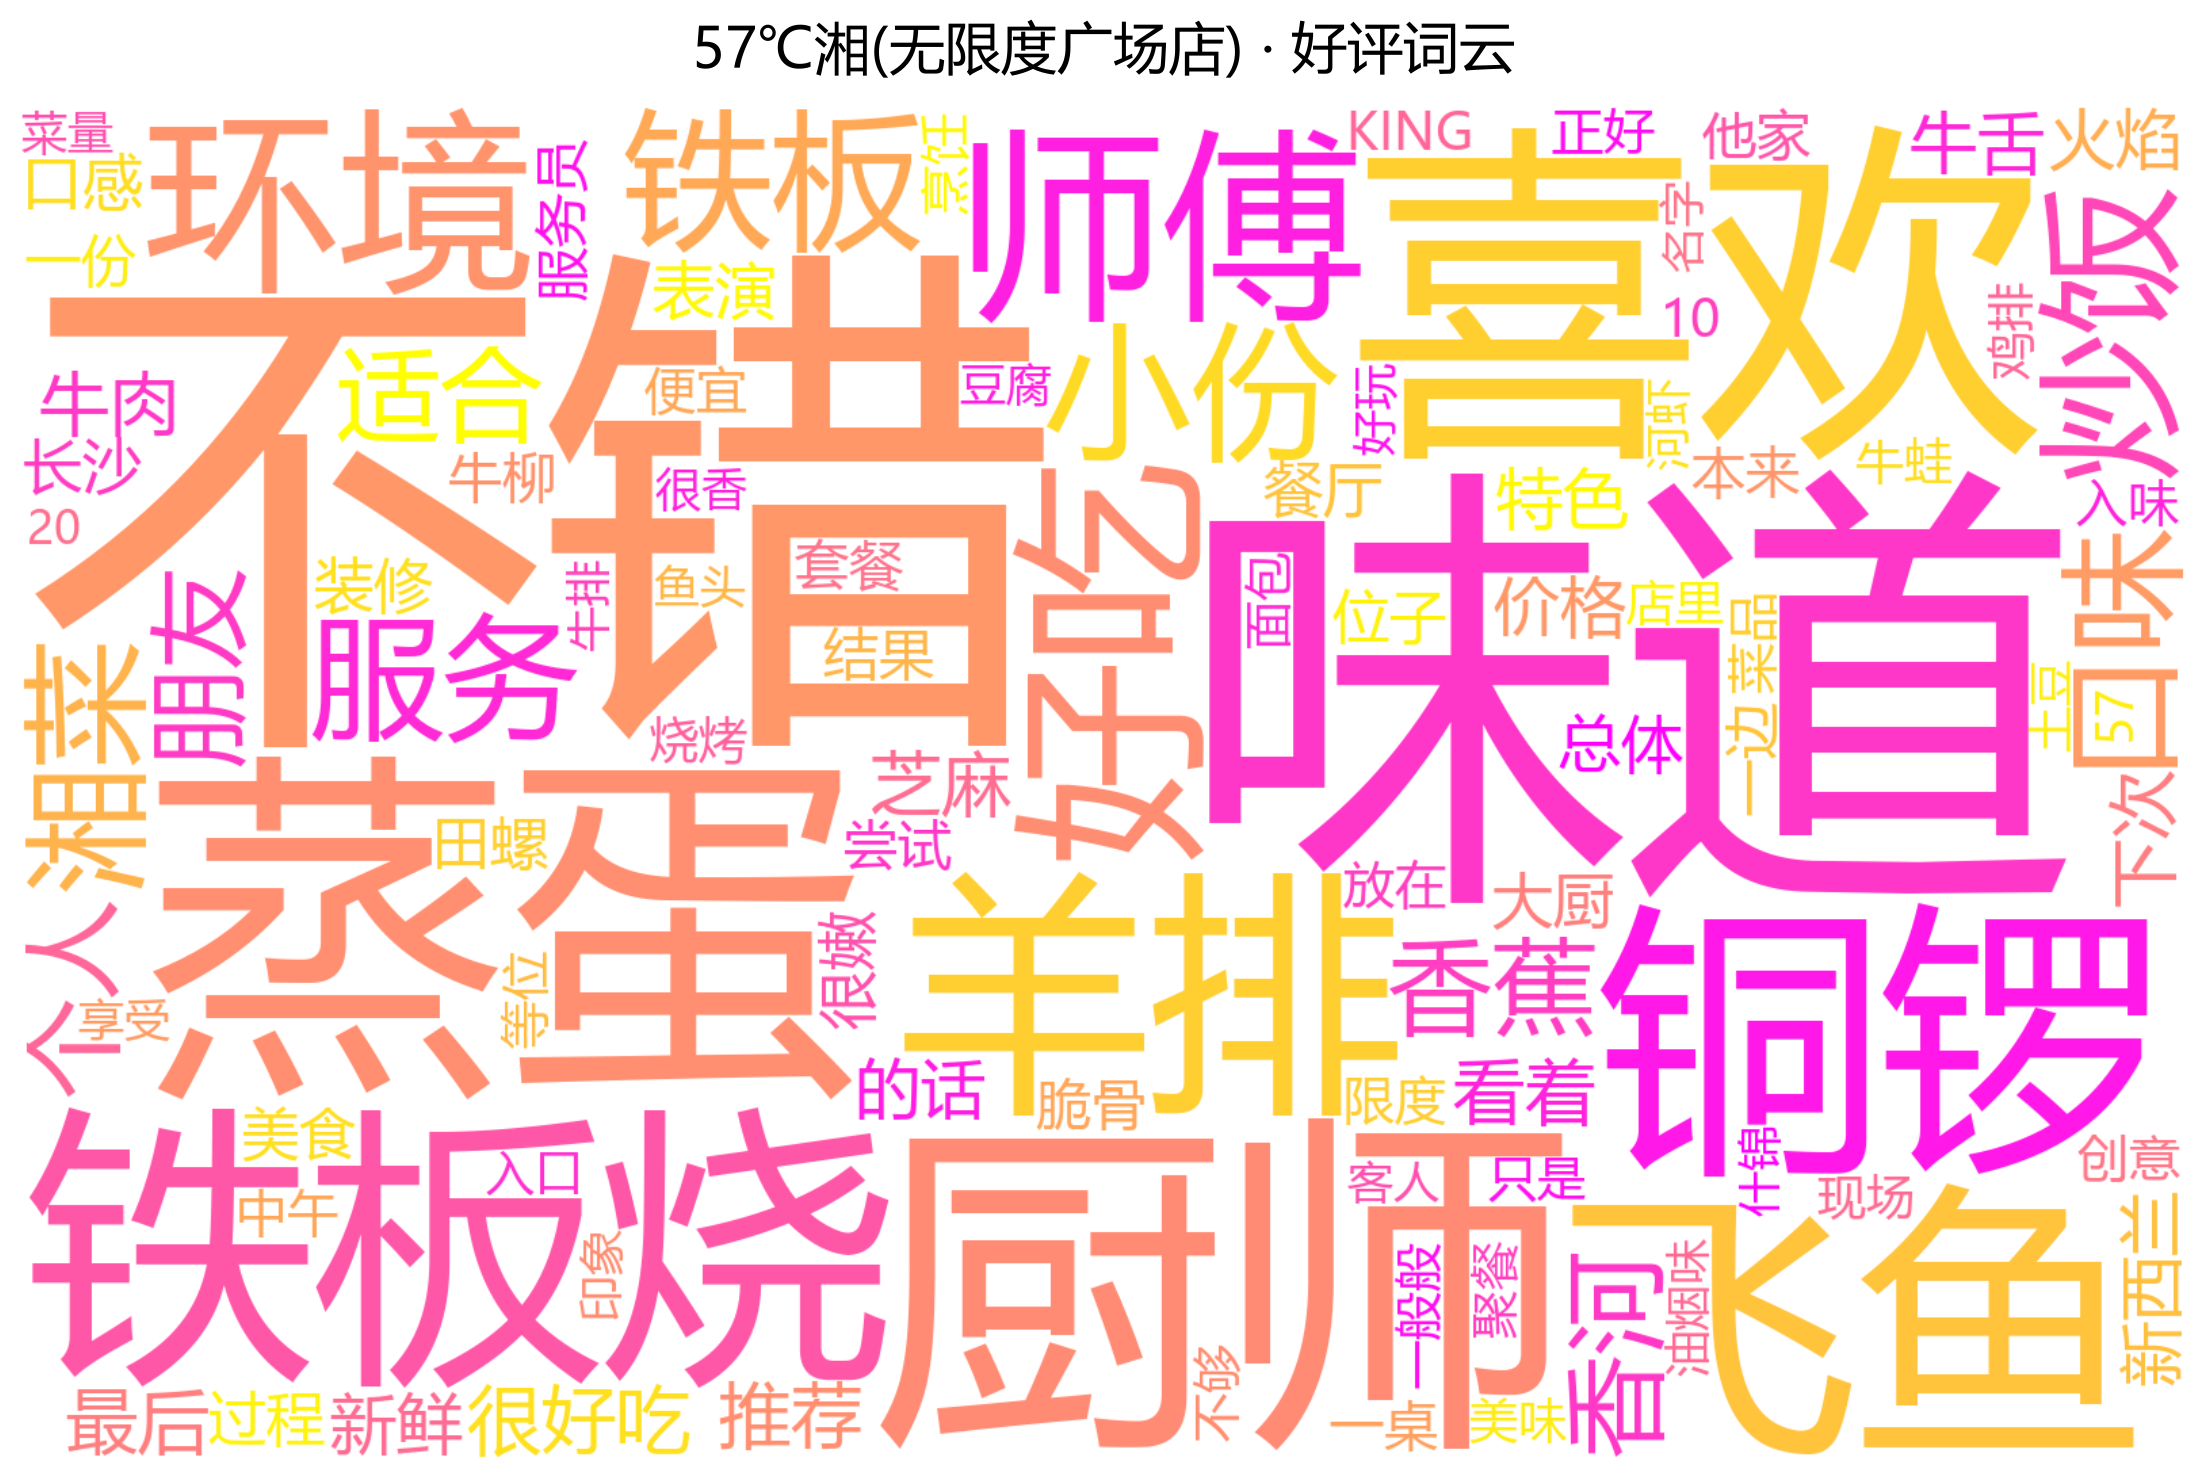

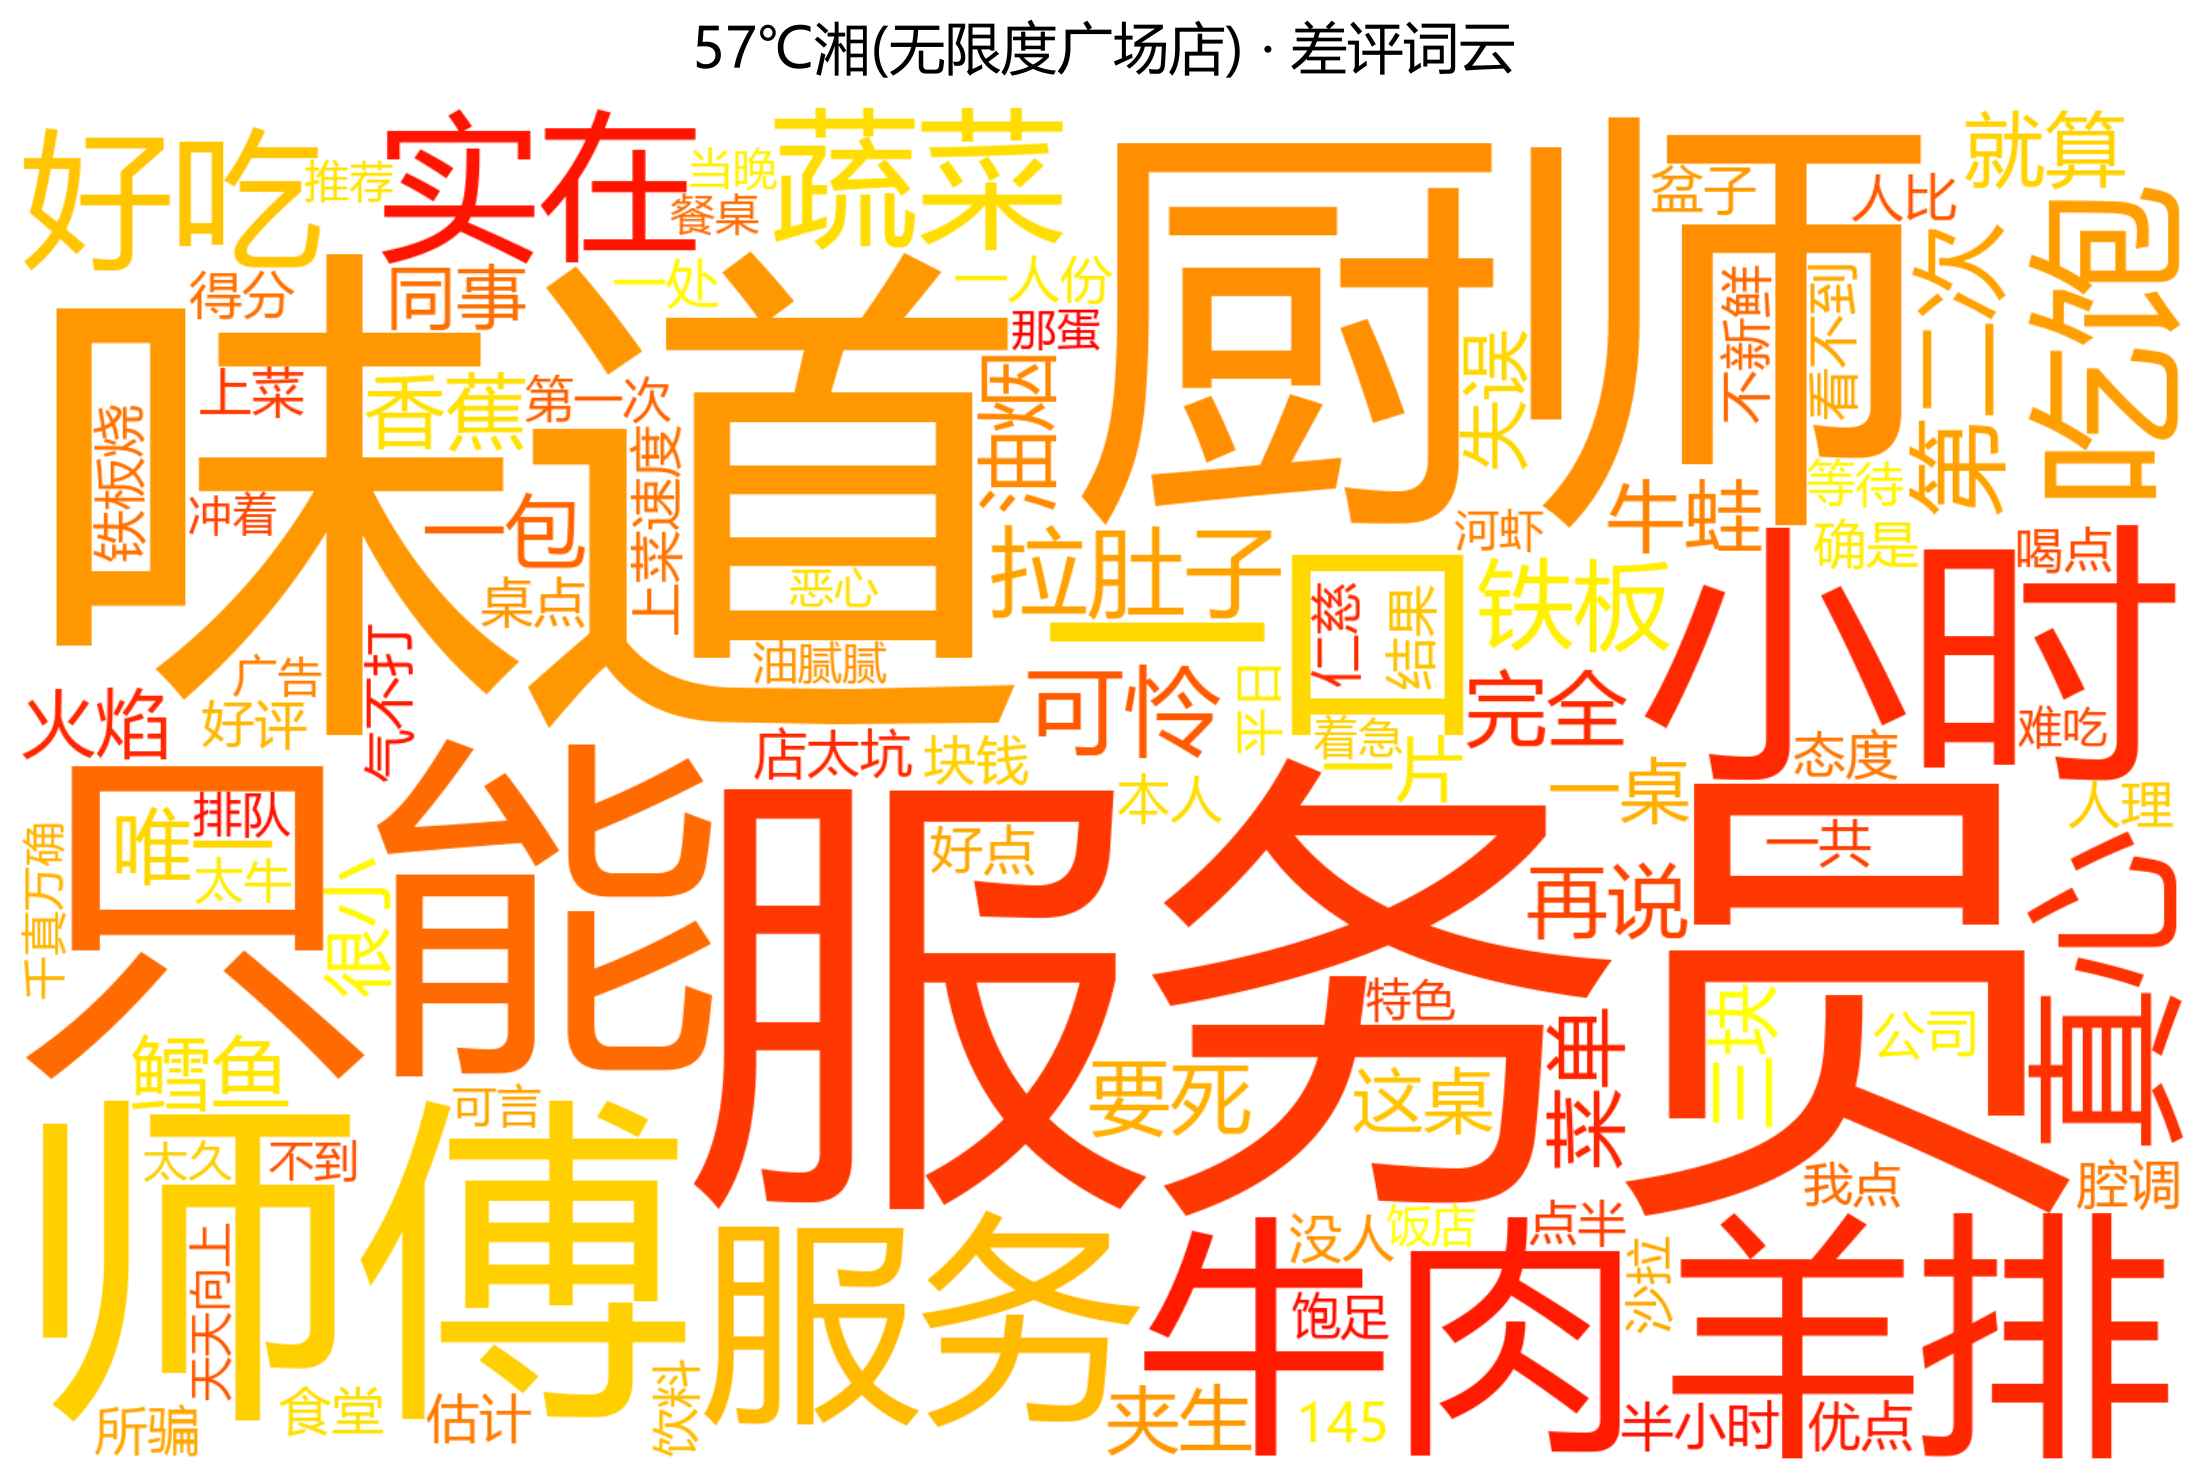

In [5]:
fig = viz_utils.plot_wordcloud(counters["all"], f"{DEMO_NAME} · 全部评论词云",
                               "fig11_2_rest_wordcloud_all.png", max_words=100, cmap="viridis")
display(Image(filename=str(fig)))
fig = viz_utils.plot_wordcloud(counters["good"], f"{DEMO_NAME} · 好评词云",
                               "fig11_2_rest_wordcloud_good.png", max_words=100, cmap="spring")
display(Image(filename=str(fig)))
fig = viz_utils.plot_wordcloud(counters["bad"], f"{DEMO_NAME} · 差评词云",
                               "fig11_2_rest_wordcloud_bad.png", max_words=100, cmap="autumn")
display(Image(filename=str(fig)))

## 11.3 该商户好评率（按总体评分）

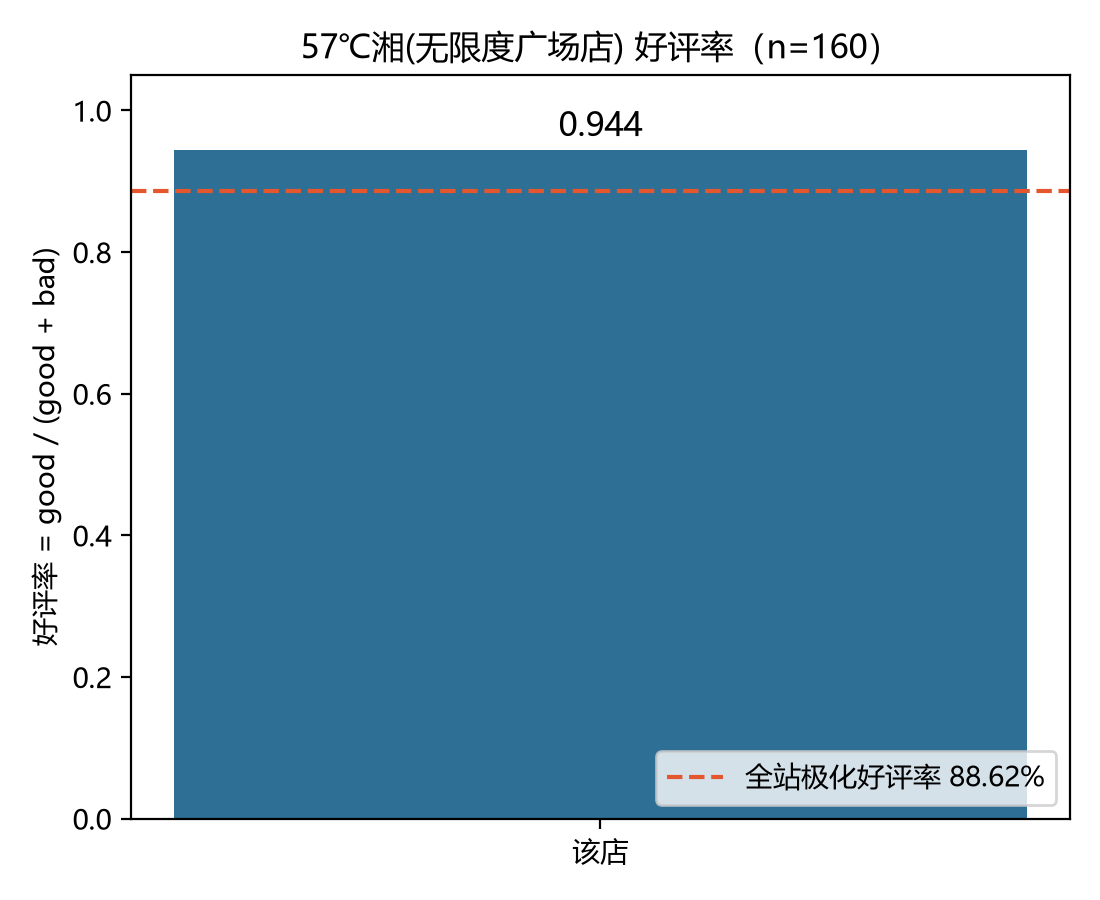

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.bar(["该店"], [row["ratio"]], color="#2e6f95", width=0.5)
ax.axhline(0.8862, ls="--", color="#e4572e", label="全站极化好评率 88.62%")
ax.text(0, row["ratio"] + 0.02, "%.3f" % row["ratio"], ha="center", fontsize=12)
ax.set_ylim(0, 1.05); ax.set_ylabel("好评率 = good / (good + bad)")
ax.set_title(f"{DEMO_NAME} 好评率（n={int(row['lab'])}）")
ax.legend(loc="lower right")
fig.tight_layout()
out = FIG / "fig11_3_rest_ratio.png"
fig.savefig(out, dpi=200); plt.close(fig)
display(Image(filename=str(out)))

## 11.4 该商户环境 / 口味 / 服务雷达图

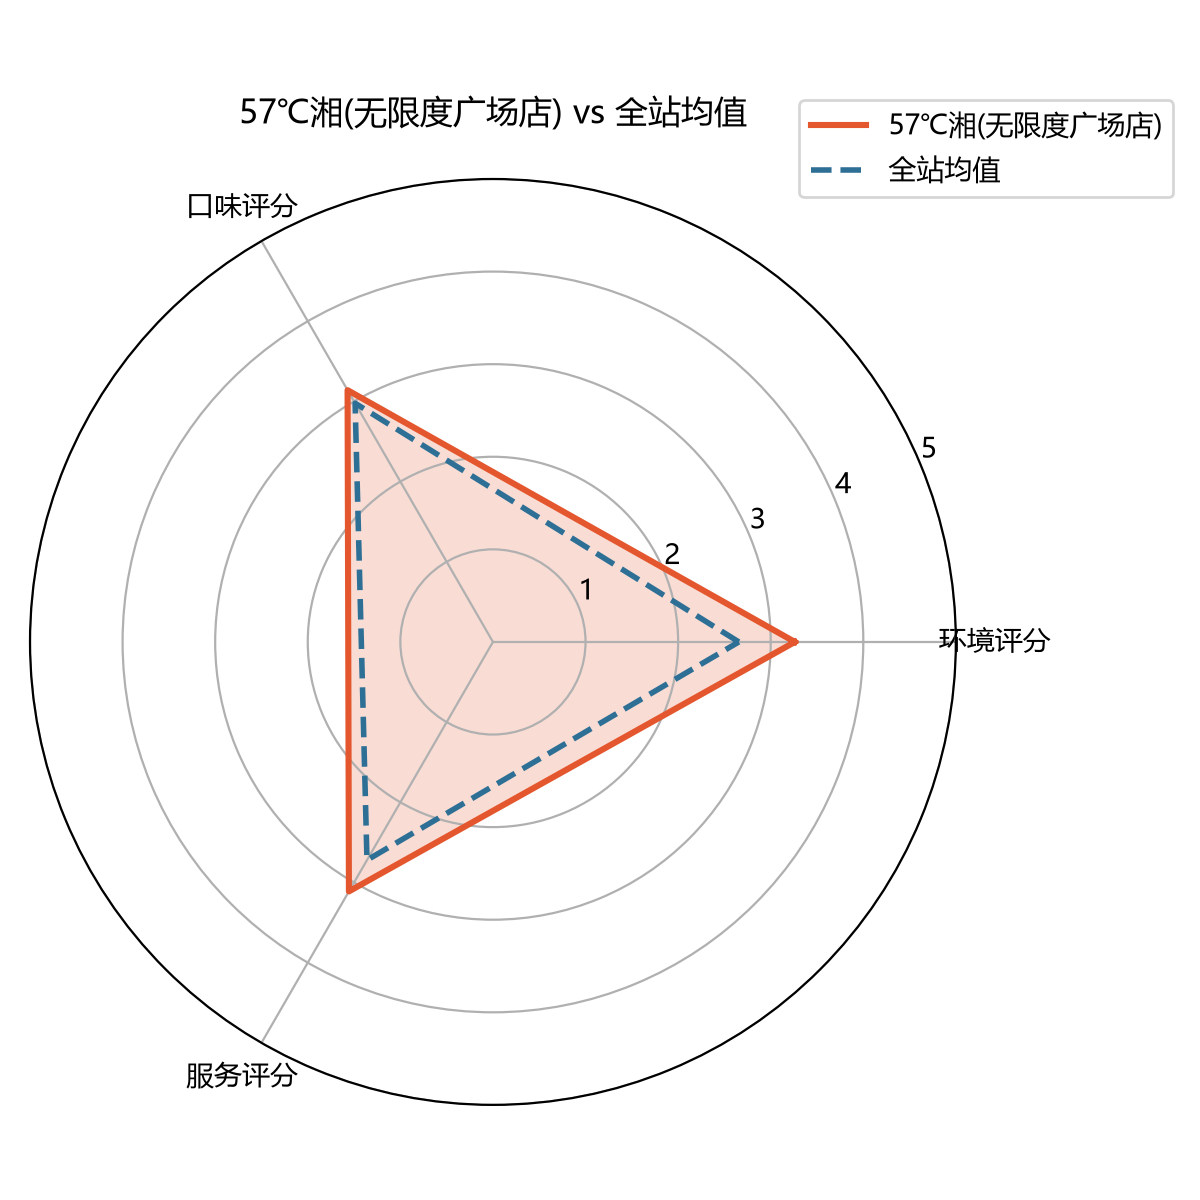

In [7]:
cats = ["环境评分", "口味评分", "服务评分"]
vals = [row["env_mean"], row["flavor_mean"], row["service_mean"]]
site = [agg["env_mean"].mean(), agg["flavor_mean"].mean(), agg["service_mean"].mean()]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"polar": True})
angles = np.linspace(0, 2 * np.pi, len(cats), endpoint=False).tolist()
angles += angles[:1]
ax.set_xticks(angles[:-1]); ax.set_xticklabels(cats)
ax.set_ylim(0, 5)
ax.plot(angles, vals + vals[:1], lw=2.2, color="#e4572e", label=DEMO_NAME)
ax.fill(angles, vals + vals[:1], color="#e4572e", alpha=0.2)
ax.plot(angles, site + site[:1], lw=2.0, ls="--", color="#2e6f95", label="全站均值")
ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.1))
ax.set_title(f"{DEMO_NAME} vs 全站均值", pad=20)
fig.tight_layout()
out = FIG / "fig11_4_rest_radar.png"
fig.savefig(out, dpi=200); plt.close(fig)
display(Image(filename=str(out)))

## 11.5 该商户随时间的周好评率

活跃周数: 20 | 周有效样本中位数: 9.0


,week,good,n,ratio_roll
8,2011-10-31/2011-11-06,12,12,1.000000
9,2011-11-07/2011-11-13,7,7,1.000000
10,2011-11-14/2011-11-20,8,9,0.964286
11,2011-12-12/2011-12-18,3,3,0.967742
12,2011-12-19/2011-12-25,10,11,0.933333
13,2011-12-26/2012-01-01,12,13,0.916667
14,2012-01-02/2012-01-08,10,11,0.921053
15,2012-01-09/2012-01-15,11,11,0.934783
16,2012-01-16/2012-01-22,7,7,0.952381
17,2012-01-23/2012-01-29,8,10,0.923077


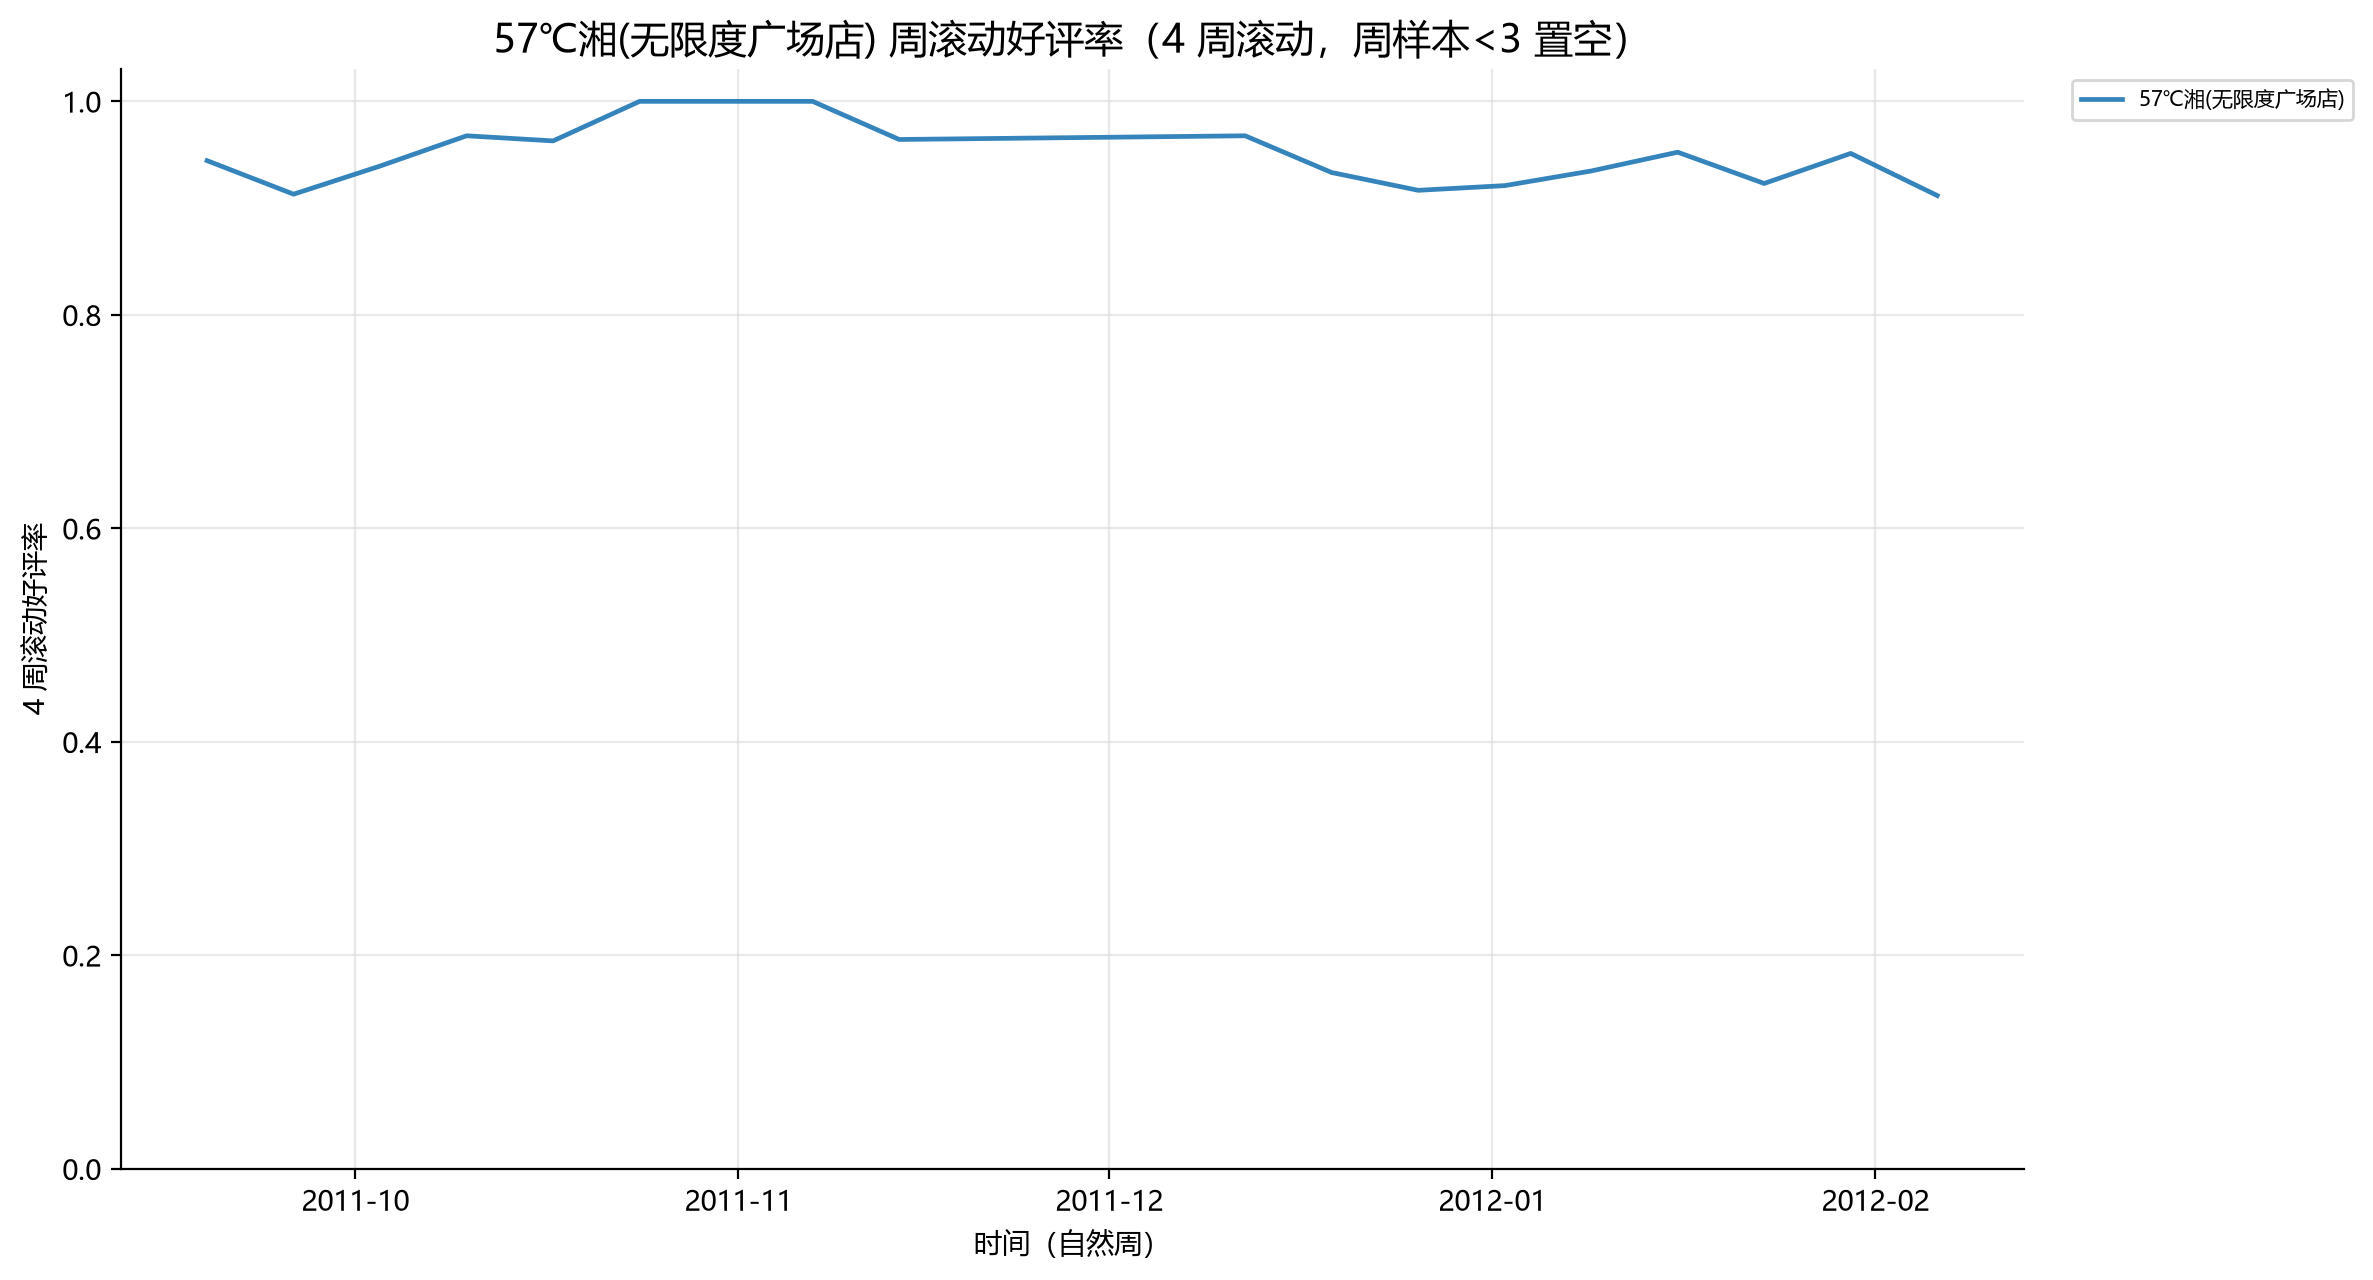

In [8]:
polar = sub[sub["label"].isin([0, 1])].copy()
polar["week"] = pd.to_datetime(polar["timestamp"], unit="ms").dt.to_period("W")
wk = weekly_counts(polar, [DEMO_ID])
wk_roll = rolling_ratio(wk, window=4, min_labels=3, roll_min=6)
print("活跃周数:", len(wk), "| 周有效样本中位数:", float(np.median(wk["n"])))
display(wk_roll[["week", "good", "n", "ratio_roll"]].tail(12))

fig = viz_utils.plot_weekly_lines(
    wk_roll, {DEMO_ID: DEMO_NAME}, "fig11_5_rest_weekly_ratio.png",
    f"{DEMO_NAME} 周滚动好评率（4 周滚动，周样本<3 置空）")
display(Image(filename=str(fig)))

## 交互接口

`run_query()` 支持在终端 / Jupyter 中直接输入关键词并选择商户（notebook 中执行会阻塞等待输入，故此处只定义不调用）：

```python
def run_query():
    kw = input("请输入关键词（如 湘/粤/人大/北大/西直门）：")
    cands = search_restaurants(kw, agg, topk=20)
    print(cands[["display", "n", "lab", "ratio"]].to_string())
    idx = int(input("请选择候选序号（0 开始）："))
    rid = int(cands.iloc[idx]["restId"])
    ...  # 复用 11.2-11.5 的四段代码
```


## 小结

- 关键词同时检索名称与评论，命中商户按极化样本量排序，可避免选中样本过少的店；
- 演示店 `57℃湘(无限度广场店)`：207 条评论、160 条极化样本、20 个活跃周，四张图均可用；
- 交互函数与四段分析代码可复用到任意商户。